# Kernels CUDA na prática
## 1. Introdução: a pergunta

Para cada elemento de um vetor, queremos calcular:

$$y[i] = (x[i] + \alpha) \times \beta + \gamma$$

São **três operações matemáticas por elemento** nas duas versões. Como a mesma conta pode ficar **~3× mais rápida**?

> Em GPUs, o tempo muitas vezes é limitado pelo movimento dos dados, não pelo número de operações matemáticas.

**Fio condutor:** mesma matemática → mesmo número de operações matemáticas → caminho diferente pelos dados → menos tráfego de memória → menos kernel launches → menor tempo.

## Mapa do notebook

1. Ambiente CUDA — seção 2
2. Conceitos CUDA — seção 3
3. Primeiro kernel — seção 4
4. Grid, blocks e threads — seção 5
5. Tamanho do block — seção 6
6. Memória da GPU — seção 7
7. Kernel fusion — seção 8
8. Benchmark final — seção 9
9. Resposta — seção 10

## 2. Ambiente CUDA e GPU utilizada

Execute esta célula primeiro. Os tempos abaixo foram obtidos em uma **RTX 3050 Laptop**; ao executar em outra GPU, os números podem mudar.

In [12]:
import time
from statistics import median
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

try:
    import numpy as np
except ImportError as exc:
    raise RuntimeError("Instale NumPy para executar este notebook.") from exc

try:
    import cupy as cp
    device_count = cp.cuda.runtime.getDeviceCount()
    if device_count < 1:
        raise RuntimeError("Nenhuma GPU CUDA foi detectada.")
    gpu = cp.cuda.Device()
    props = cp.cuda.runtime.getDeviceProperties(gpu.id)
    gpu.synchronize()
except Exception as exc:
    raise RuntimeError(
        "Este notebook precisa de uma GPU NVIDIA com CUDA funcional e de uma versão "
        "do CuPy compatível com o CUDA instalado. Verifique o driver, o CUDA e o CuPy."
    ) from exc

name = props["name"]
if isinstance(name, bytes):
    name = name.decode(errors="replace")
vram_gib = props["totalGlobalMem"] / 1024**3
rng = np.random.default_rng(42)

# Medimos a mediana; warm-up e compilação ficam fora da medição.
def cpu_ms(fn, repeats=7):
    fn()  # warm-up
    samples = []
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        samples.append((time.perf_counter() - start) * 1e3)
    return median(samples)

def gpu_ms(fn, repeats=15):
    fn()  # compilação/warm-up fora da medição
    cp.cuda.Stream.null.synchronize()
    samples = []
    for _ in range(repeats):
        start, end = cp.cuda.Event(), cp.cuda.Event()
        start.record()
        fn()
        end.record()
        end.synchronize()
        samples.append(cp.cuda.get_elapsed_time(start, end))
    return median(samples)

cuda_version = cp.cuda.runtime.runtimeGetVersion()
cuda_major = cuda_version // 1000
cuda_minor = (cuda_version % 1000) // 10
compute_capability = f"{props['major']}.{props['minor']}"
display(Markdown(
    f"**GPU**\n\n"
    f"- Nome: {name}\n"
    f"- Memória global: {vram_gib:.1f} GiB\n"
    f"- Compute Capability: {compute_capability}\n"
    f"- CUDA runtime: {cuda_major}.{cuda_minor}\n\n"
    f"**Bibliotecas:** CuPy {cp.__version__} · NumPy {np.__version__} · Matplotlib {plt.matplotlib.__version__}"
))

**GPU**

- Nome: NVIDIA GeForce RTX 3050 Laptop GPU
- Memória global: 3.7 GiB
- Compute Capability: 8.6
- CUDA runtime: 13.2

**Bibliotecas:** CuPy 14.2.0 · NumPy 2.5.3 · Matplotlib 3.11.2

### Por que CUDA Events?

A CPU pode retornar do kernel launch antes de a GPU terminar. Por isso, a sequência usada em `gpu_ms` mede a linha do tempo da GPU:

```python
start.record()
kernel()
end.record()
end.synchronize()
```

Uma execução inicial é feita como **warm-up** para tirar compilação/JIT e inicializações da medição. Referência: [medição com CUDA Events no CuPy](https://docs.cupy.dev/en/stable/user_guide/performance.html#benchmarking).

## 3. Conceitos CUDA necessários

| Termo | Papel neste notebook |
|---|---|
| **Host (CPU)** | Prepara os dados e lança o kernel. |
| **Device (GPU)** | Executa o kernel e armazena os vetores na VRAM. |
| **Kernel CUDA** | Função executada por muitas threads. |
| **Thread** | Calcula um elemento do vetor neste kernel. |
| **Block** | Grupo de threads atribuído a um SM (Streaming Multiprocessor). |
| **Grid** | Conjunto de blocks de um lançamento. |

```text
CPU / Host
    |
    | prepara dados
    | define grid e block
    | lança kernel
    v
GPU / Device
    |
    | executa threads
    | acessa dados da VRAM
    v
resultado
```

O código Python/CuPy roda no host. O código dentro de `__global__` roda no device.

## 4. Primeiro kernel: `vector_add`

Antes da expressão principal, somamos dois vetores: $C[i] = A[i] + B[i]$.

> Neste kernel escolhemos **1 thread → 1 elemento**. CUDA não exige isso: uma thread pode processar vários elementos ou estruturas mais complexas.

- `__global__` → função executada na GPU e lançada pelo host.
- `extern "C"` → evita alteração do nome do símbolo pelo C++, facilitando ao `RawKernel` localizar `"vector_add"`.

### CUDA C através de `cp.RawKernel`

CuPy permite escrever CUDA C explicitamente através de `RawKernel`. O código CUDA é fornecido como uma string, compilado para execução na GPU e depois lançado pelo Python.

```text
Python / CuPy:
    vector_add(grid, (block,), (...))

CUDA C++ equivalente conceitualmente:
    vector_add<<<grid, block>>>(...)
```

`grid` define quantos blocks; `block` define quantas threads por block; o último argumento contém os parâmetros do kernel.

<small>Referência: [RawKernel na documentação do CuPy](https://docs.cupy.dev/en/stable/user_guide/kernel.html#raw-kernels).</small>

In [13]:
# A mesma operação: C = A + B
a_cpu = np.arange(8, dtype=np.float32)
b_cpu = np.full(8, 2, dtype=np.float32)
c_cpu = np.empty_like(a_cpu)
np.add(a_cpu, b_cpu, out=c_cpu)

vector_add_source = r"""
extern "C" __global__
void vector_add(const float* A, const float* B, float* C, int N) {
    int i = blockIdx.x * blockDim.x + threadIdx.x; // índice global
    if (i < N) {
        C[i] = A[i] + B[i];
    }
}
"""
vector_add = cp.RawKernel(vector_add_source, "vector_add")
a_gpu, b_gpu = cp.asarray(a_cpu), cp.asarray(b_cpu)
c_gpu = cp.empty_like(a_gpu)
block = 256
grid = ((a_gpu.size + block - 1) // block,)
vector_add(grid, (block,), (a_gpu, b_gpu, c_gpu, np.int32(a_gpu.size)))
cp.cuda.Stream.null.synchronize()
assert np.allclose(c_cpu, cp.asnumpy(c_gpu))
display(Markdown("**Resultado:** CPU e kernel CUDA calcularam o mesmo vetor."))

**Resultado:** CPU e kernel CUDA calcularam o mesmo vetor.

### Tipos dos parâmetros na chamada

```text
a_gpu                 → const float* A
b_gpu                 → const float* B
c_gpu                 → float* C
np.int32(a_gpu.size)   → int N
```

Usamos `np.int32` porque o kernel declarou `int N`: queremos passar um inteiro de 32 bits compatível com a assinatura CUDA/C++.

### Como a thread encontra seu elemento?

`i = blockIdx.x * blockDim.x + threadIdx.x`: `blockIdx.x * blockDim.x` aponta para o início do block, e `threadIdx.x` indica a posição da thread dentro dele.

```text
índice global = início do block + posição da thread dentro do block

blockDim.x  = 256
blockIdx.x  = 3
threadIdx.x = 10

i = 3 × 256 + 10 = 778
C[778] = A[778] + B[778]
```

O teste `i < N` protege o último block, que pode sobrar parcialmente; o índice 778 só é usado se estiver dentro do vetor.

In [14]:
# Exemplo de índices globais com 256 threads por block.
threads_per_block = 256
for block_id in (0, 1):
    first = block_id * threads_per_block
    last = first + threads_per_block - 1
    print(f"Block {block_id}: threads globais {first}–{last}")

Block 0: threads globais 0–255
Block 1: threads globais 256–511


## 5. Configuração de execução: grid, blocks e threads

Escolhemos **threads por block**. A grid precisa de blocks suficientes para cobrir todos os $N$ elementos:

$$\text{blocks} = \left\lceil \frac{N}{\text{threads por block}} \right\rceil$$

Como usamos inteiros, `(N + block - 1) // block` arredonda a divisão **para cima**. Por exemplo, 1.025 elementos com blocks de 256 threads precisam de 5 blocks; o último usa só 1 thread ativa para esse vetor.

| Threads/block | Warps/block (32 threads cada) |
|---:|---:|
| 32 | 1 |
| 64 | 2 |
| 128 | 4 |
| 256 | 8 |
| 512 | 16 |

```text
threads por block
    ↓
warps por block
    ↓
blocks residentes por SM
    ↓
warps residentes
    ↓
capacidade de esconder latência
```

**256 threads/block = 8 warps/block**; isso não torna 256 um valor ideal. A quantidade de blocks e warps residentes também depende dos limites de recursos do kernel e da GPU.

### O que estamos cronometrando?

Mantemos o experimento de soma vetorial que compara **CPU**, **somente kernel** e **transferência CPU → GPU → CPU**. O custo de copiar os dados pode dominar a execução.

In [15]:
# CPU, somente kernel e ida + volta: três perguntas diferentes.
rows = []
for n in (4_096, 262_144, 2_000_000):
    a_host = rng.random(n, dtype=np.float32)
    b_host = rng.random(n, dtype=np.float32)
    cpu_out = np.empty_like(a_host)
    returned = np.empty_like(a_host)
    d_a, d_b = cp.asarray(a_host), cp.asarray(b_host)
    d_out = cp.empty_like(d_a)
    grid = ((n + block - 1) // block,)

    def launch():
        vector_add(grid, (block,), (d_a, d_b, d_out, np.int32(n)))

    cpu_time = cpu_ms(lambda: np.add(a_host, b_host, out=cpu_out))
    kernel_time = gpu_ms(launch)

    def end_to_end():
        d_a.set(a_host)                # CPU → GPU
        d_b.set(b_host)                # CPU → GPU
        launch()
        d_out.get(out=returned)        # GPU → CPU
        cp.cuda.Stream.null.synchronize()

    total_time = cpu_ms(end_to_end, repeats=5)
    assert np.allclose(cpu_out, returned)
    rows.append((n, cpu_time, kernel_time, total_time))

table = "| Elementos | NumPy CPU (ms) | Só kernel (ms) | Ida + volta (ms) |\n"
table += "|---:|---:|---:|---:|\n"
for n, cpu_t, kernel_t, total_t in rows:
    table += f"| {n:,} | {cpu_t:.4f} | {kernel_t:.4f} | {total_t:.4f} |\n"
display(Markdown(table + "\n> **Takeaway:** Kernel rápido não garante aplicação rápida. Lançamento e transferências também custam tempo. A coluna final inclui transferências e lançamento, com buffers pré-alocados; a CPU já tem os dados."))


| Elementos | NumPy CPU (ms) | Só kernel (ms) | Ida + volta (ms) |
|---:|---:|---:|---:|
| 4,096 | 0.0024 | 0.0084 | 0.0312 |
| 262,144 | 0.0908 | 0.0224 | 0.3881 |
| 2,000,000 | 0.8571 | 0.1362 | 2.9319 |

> **Takeaway:** Kernel rápido não garante aplicação rápida. Lançamento e transferências também custam tempo. A coluna final inclui transferências e lançamento, com buffers pré-alocados; a CPU já tem os dados.

### Detalhe de medição: lançar não é esperar

O kernel launch normalmente enfileira trabalho, e a CPU pode continuar. `synchronize` espera a GPU; CUDA Events medem a execução no device, como em `gpu_ms`.

O experimento abaixo compara o tempo percebido pela CPU após o lançamento com o tempo até a GPU terminar.

In [16]:
# Um kernel demonstrativo que ocupa uma thread por ~12 ms.
# Assim fica visível a diferença entre enfileirar e esperar.
wait_source = r"""
extern "C" __global__
void wait_kernel(unsigned long long cycles, unsigned long long* out) {
    unsigned long long t0 = clock64();
    while (clock64() - t0 < cycles) {}
    out[0] = clock64() - t0;
}
"""
wait_kernel = cp.RawKernel(wait_source, "wait_kernel")
wait_out = cp.empty(1, dtype=cp.uint64)
cycles = np.uint64(12 * props["clockRate"])  # clockRate em ciclos por milissegundo
wait_kernel((1,), (1,), (np.uint64(0), wait_out))  # JIT/warm-up fora da medida
cp.cuda.Stream.null.synchronize()

start = time.perf_counter()
wait_kernel((1,), (1,), (cycles, wait_out))
enqueue_ms = (time.perf_counter() - start) * 1e3
cp.cuda.Stream.null.synchronize()
complete_ms = (time.perf_counter() - start) * 1e3

display(Markdown(
    f"| Observação da CPU | Tempo (ms) |\n|---|---:|\n"
    f"| Após lançar, sem esperar | {enqueue_ms:.3f} |\n"
    f"| Até a GPU terminar | {complete_ms:.3f} |\n\n"
    "    CPU: lança ───── continua ───── synchronize\n"
    "    GPU:       └── kernel executando ─┘\n\n"
    "> **Takeaway:** O lançamento normalmente enfileira trabalho; a CPU pode continuar. "
    "Operações na mesma stream preservam a ordem."
))


| Observação da CPU | Tempo (ms) |
|---|---:|
| Após lançar, sem esperar | 0.358 |
| Até a GPU terminar | 12.235 |

    CPU: lança ───── continua ───── synchronize
    GPU:       └── kernel executando ─┘

> **Takeaway:** O lançamento normalmente enfileira trabalho; a CPU pode continuar. Operações na mesma stream preservam a ordem.

## 6. Benchmark: tamanho do block

**Mesmo kernel. Mesmo número de elementos. Apenas mudamos threads por block.** Os vetores já estão na GPU, e a tabela mede somente o kernel.

Observe o salto de 32 para 64 threads e o **platô entre 64 e 512** nesta medição. Não existe tamanho universal ótimo: depende do kernel e da GPU.

> O caso de 32 threads/block ficou significativamente mais lento nesta GPU e neste kernel. Isso é compatível com menor disponibilidade de warps para esconder latências ou outros limites de recursos, mas o benchmark sozinho não prova a causa exata.

In [17]:
# Mesmo kernel; só o tamanho do block muda. Entradas já estão na GPU.
n = 2_000_000
d_a = cp.asarray(rng.random(n, dtype=np.float32))
d_b = cp.asarray(rng.random(n, dtype=np.float32))
d_out = cp.empty_like(d_a)
block_rows = []
for threads in (32, 64, 128, 256, 512):
    blocks = (n + threads - 1) // threads
    def launch_for_block():
        vector_add((blocks,), (threads,), (d_a, d_b, d_out, np.int32(n)))
    block_rows.append((threads, gpu_ms(launch_for_block)))

table = "| Threads/block | Só kernel (ms) |\n|---:|---:|\n"
for threads, elapsed in block_rows:
    table += f"| {threads} | {elapsed:.4f} |\n"
display(Markdown(table + "\n> **Takeaway:** O tamanho do block afeta agendamento, recursos e **occupancy**. O melhor valor depende do kernel e da GPU."))


| Threads/block | Só kernel (ms) |
|---:|---:|
| 32 | 0.2191 |
| 64 | 0.1393 |
| 128 | 0.1362 |
| 256 | 0.1362 |
| 512 | 0.1362 |

> **Takeaway:** O tamanho do block afeta agendamento, recursos e **occupancy**. O melhor valor depende do kernel e da GPU.

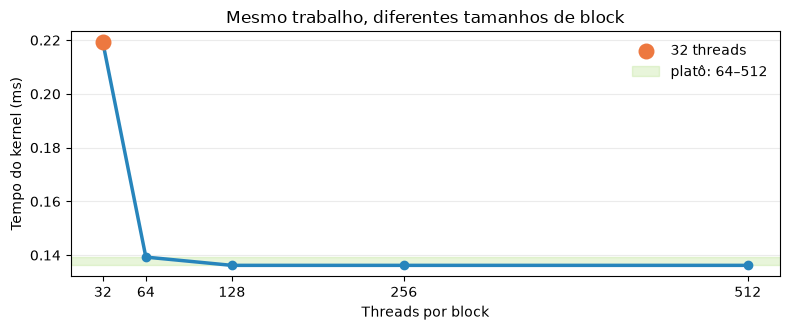

In [18]:
# Os pontos vêm da tabela acima; o gráfico acompanha novas execuções.
threads, times_ms = zip(*block_rows)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(threads, times_ms, marker="o", color="#2785bc", linewidth=2.5)
ax.scatter([threads[0]], [times_ms[0]], s=110, color="#ed7840", zorder=3, label="32 threads")
ax.axhspan(min(times_ms[1:]), max(times_ms[1:]), color="#a5d86d", alpha=.25, label="platô: 64–512")
ax.set(xlabel="Threads por block", ylabel="Tempo do kernel (ms)", title="Mesmo trabalho, diferentes tamanhos de block")
ax.set_xticks(threads)
ax.grid(axis="y", alpha=.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Até aqui: como executar.
## Agora: quanto custa alimentar a execução?

Uma GPU pode executar muitas operações em paralelo, mas essas operações precisam receber dados. Se trazer e armazenar os dados custa mais tempo que a aritmética, o kernel torna-se **memory-bound**.

## 7. Memória da GPU: onde os dados ficam

```text
Registradores
- privados da thread
- on-chip
- usados para temporários
    ↓
Shared memory
- compartilhada pelas threads do mesmo block
- on-chip
- útil para cooperação/reuso
    ↓
Caches
- gerenciados principalmente pelo hardware
    ↓
Global memory / VRAM
- grande
- acessível pelos kernels
- maior custo de acesso
```

Uma thread **não lê diretamente os registradores privados de outra thread**. Em nosso exemplo, `x`, `a`, `b` e `y` são vetores na global memory. **Mover dados pode custar mais que fazer a conta.**

<small>Local memory em CUDA não significa necessariamente memória fisicamente próxima: ela pode residir na memória global, por exemplo em casos de register spilling. Referência: [memórias no guia CUDA](https://docs.nvidia.com/cuda/cuda-programming-guide/02-basics/writing-cuda-kernels.html).</small>

Threads consecutivas acessam `A[i]`, `B[i]` e `C[i]` consecutivos na memória. Isso favorece **memory coalescing**, permitindo ao hardware combinar acessos da warp em transações eficientes.

## 8. Kernel fusion: três kernels ou um kernel fundido?

Em ambos os caminhos calculamos $y[i] = (x[i] + \alpha) \times \beta + \gamma$.

### A matemática não muda. O caminho dos dados muda.

```text
Sem fusão                 Com fusão

VRAM x                    VRAM x
   ↓                         ↓
 + α                      registrador v
   ↓                         ↓
VRAM a                     + α
   ↓                         ↓
 × β                       × β
   ↓                         ↓
VRAM b                     + γ
   ↓                         ↓
 + γ                      VRAM y
   ↓
VRAM y
```

Os intermediários `a` e `b` deixam de ser vetores na VRAM; o caminho da direita representa o caso em que o compilador mantém `v` em registrador.



<small>Diagrama do experimento: tráfego lógico simplificado para valores `float32`.</small>

In [ ]:
# Três RawKernels explícitos: etapas separadas.
separate_source = r"""
extern "C" __global__
void add_kernel(const float* x, float* a, float alpha, int N) {
    int i = blockIdx.x * blockDim.x + threadIdx.x; // uma thread por elemento
    if (i < N) a[i] = x[i] + alpha;
}

extern "C" __global__
void multiply_kernel(const float* a, float* b, float beta, int N) {
    int i = blockIdx.x * blockDim.x + threadIdx.x; // uma thread por elemento
    if (i < N) b[i] = a[i] * beta;
}

extern "C" __global__
void final_add_kernel(const float* b, float* y, float gamma, int N) {
    int i = blockIdx.x * blockDim.x + threadIdx.x; // uma thread por elemento
    if (i < N) y[i] = b[i] + gamma;
}
"""
add_kernel = cp.RawKernel(separate_source, "add_kernel")
multiply_kernel = cp.RawKernel(separate_source, "multiply_kernel")
final_add_kernel = cp.RawKernel(separate_source, "final_add_kernel")


In [ ]:
# Um RawKernel explícito: versão fundida.
fused_source = r"""
extern "C" __global__
void fused_kernel(const float* x, float* y,
                  float alpha, float beta, float gamma, int N) {
    int i = blockIdx.x * blockDim.x + threadIdx.x; // uma thread por elemento
    if (i < N) {
        float v = x[i];
        v = v + alpha;
        v = v * beta;
        v = v + gamma;
        y[i] = v;
    }
}
"""
fused_kernel = cp.RawKernel(fused_source, "fused_kernel")


> Em `float v = x[i];`, `v` é privado da thread e **pode ser mantido em registrador** pelo compilador. Assim, os resultados intermediários não precisam ser materializados como arrays completos na memória global.

## 9. Benchmark final: mesma matemática, outro caminho

Medimos os buffers **já na GPU** e verificamos a igualdade numérica das duas versões. O tempo dos três kernels inclui os três lançamentos na stream; o tempo fundido inclui um lançamento.

In [20]:
# Buffers alocados antes de qualquer medição.
n_fusion = 2_000_000
x_host = rng.random(n_fusion, dtype=np.float32)
x = cp.asarray(x_host)
a = cp.empty_like(x)
b = cp.empty_like(x)
y_separate = cp.empty_like(x)
y_fused = cp.empty_like(x)
alpha, beta, gamma = np.float32(1.25), np.float32(0.75), np.float32(-0.25)
grid_fusion = ((n_fusion + block - 1) // block,)

def run_separate():
    add_kernel(grid_fusion, (block,), (x, a, alpha, np.int32(n_fusion)))
    multiply_kernel(grid_fusion, (block,), (a, b, beta, np.int32(n_fusion)))
    final_add_kernel(grid_fusion, (block,), (b, y_separate, gamma, np.int32(n_fusion)))

def run_fused():
    fused_kernel(grid_fusion, (block,),
                 (x, y_fused, alpha, beta, gamma, np.int32(n_fusion)))

run_separate()  # compila e aquece os 3 kernels
run_fused()     # compila e aquece o kernel fundido
cp.cuda.Stream.null.synchronize()

reference = (x_host + alpha) * beta + gamma
assert np.allclose(reference, cp.asnumpy(y_separate), rtol=1e-5, atol=1e-6)
assert np.allclose(reference, cp.asnumpy(y_fused), rtol=1e-5, atol=1e-6)
assert bool(cp.allclose(y_separate, y_fused, rtol=1e-5, atol=1e-6))

separate_ms = gpu_ms(run_separate)
fused_ms = gpu_ms(run_fused)
speedup = separate_ms / fused_ms
display(Markdown(
    f"| Execução | Tempo GPU (ms) |\n|---|---:|\n"
    f"| 3 kernels separados | {separate_ms:.4f} |\n"
    f"| 1 kernel fundido | {fused_ms:.4f} |\n\n"
    f"**Speedup medido nesta GPU:** {speedup:.2f}× · Resultados numéricos validados."
))


| Execução | Tempo GPU (ms) |
|---|---:|
| 3 kernels separados | 0.2774 |
| 1 kernel fundido | 0.0943 |

**Speedup medido nesta GPU:** 2.94× · Resultados numéricos validados.

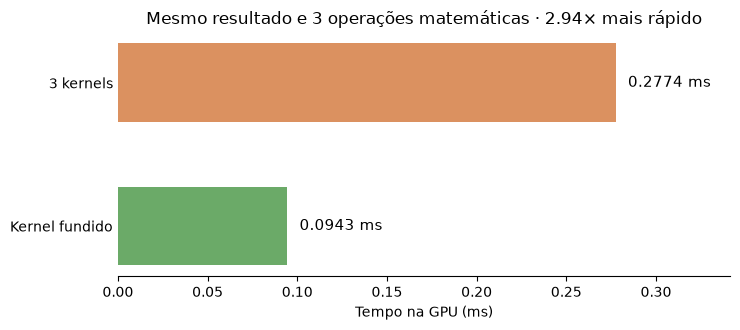

In [21]:
# Compare os tempos medidos na célula anterior.
fig, ax = plt.subplots(figsize=(7.5, 3.4))
names = ["3 kernels", "Kernel fundido"]
values = [separate_ms, fused_ms]
bars = ax.barh(names, values, color=["#db9160", "#6baa68"], height=.55)
ax.invert_yaxis()
ax.set(xlabel="Tempo na GPU (ms)", title=f"Mesmo resultado e 3 operações matemáticas · {speedup:.2f}× mais rápido")
ax.set_xlim(0, max(values) * 1.23)
for bar, value in zip(bars, values):
    ax.text(value + max(values) * .025, bar.get_y() + bar.get_height() / 2,
            f"{value:.4f} ms", va="center", fontsize=11)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
plt.show()

### Por que acelerou?

Cada `float32` ocupa **4 bytes**. O quadro abaixo conta leituras e escritas lógicas por elemento.

**Soma + multiplicação + soma = 3 FLOPs por elemento**, em ambas as versões.

In [22]:
# Modelo mínimo de tráfego global: float32 = 4 bytes; ignoramos caches.
bytes_per_value = np.dtype(np.float32).itemsize
separate_bytes_per_element = 3 * (bytes_per_value + bytes_per_value)
fused_bytes_per_element = bytes_per_value + bytes_per_value
traffic_ratio = separate_bytes_per_element / fused_bytes_per_element

display(Markdown(f"""
| Caminho | Leituras + escritas globais | Bytes/elemento |
|---|---|---:|
| add | x → a | {2 * bytes_per_value} |
| multiply | a → b | {2 * bytes_per_value} |
| final add | b → y | {2 * bytes_per_value} |
| **Separado: total** | | **{separate_bytes_per_element}** |
| **Fundido: x → y** | | **{fused_bytes_per_element}** |

Os intermediários deixam de ser arrays na VRAM; `v` pode ficar em **registrador**.
A fusão também reduz **3 lançamentos para 1**.

**Trabalho aritmético matemático:** (x + alpha) × beta + gamma = 3 operações por elemento, em ambos.
O compilador pode gerar instruções diferentes, inclusive FMA.

> **Takeaway:** O tráfego teórico cai de {separate_bytes_per_element} para {fused_bytes_per_element} bytes/elemento (**{traffic_ratio:.0f}× menos**, neste modelo). O speedup real medido foi **{speedup:.2f}×**; caches, hardware e outros gargalos mudam esse valor.
"""))


| Caminho | Leituras + escritas globais | Bytes/elemento |
|---|---|---:|
| add | x → a | 8 |
| multiply | a → b | 8 |
| final add | b → y | 8 |
| **Separado: total** | | **24** |
| **Fundido: x → y** | | **8** |

Os intermediários deixam de ser arrays na VRAM; `v` pode ficar em **registrador**.
A fusão também reduz **3 lançamentos para 1**.

**Trabalho aritmético matemático:** (x + alpha) × beta + gamma = 3 operações por elemento, em ambos.
O compilador pode gerar instruções diferentes, inclusive FMA.

> **Takeaway:** O tráfego teórico cai de 24 para 8 bytes/elemento (**3× menos**, neste modelo). O speedup real medido foi **2.94×**; caches, hardware e outros gargalos mudam esse valor.


### De 24 B para 8 B por elemento

```text
SEM FUSÃO                     COM FUSÃO

kernel 1:                     read x  = 4 B
read x  = 4 B                 write y = 4 B
write a = 4 B
                              TOTAL = 8 B/elemento
kernel 2:
read a  = 4 B
write b = 4 B

kernel 3:
read b  = 4 B
write y = 4 B

TOTAL = 24 B/elemento

24 / 8 = 3
```

Este é um **modelo lógico simplificado**. Caches podem alterar o tráfego físico efetivamente observado na DRAM.

Se o kernel fosse limitado exclusivamente pela largura de banda da memória, uma redução de tráfego próxima de 3× poderia produzir um speedup próximo de 3×. Na prática, caches, kernel launch, registradores, occupancy e outros gargalos alteram o resultado.

### Arithmetic intensity

```text
FLOPs / bytes movimentados

Separado: 3 FLOPs / 24 B = 0,125 FLOP/B
Fundido:  3 FLOPs /  8 B = 0,375 FLOP/B

arithmetic intensity aumenta 3×
```

Fizemos a mesma quantidade de aritmética por elemento, mas passamos a realizar três vezes mais trabalho matemático por byte de tráfego global no modelo simplificado.

<small>FLOPs não são contagem de instruções: o compilador pode gerar instruções diferentes, inclusive FMA. Em HPC, uma FMA costuma contar como 2 FLOPs apesar de poder ser uma única instrução. Referência: [FMA na documentação NVIDIA](https://docs.nvidia.com/cuda/floating-point/index.html#the-fused-multiply-add-fma).</small>

## 10. Conclusão: resposta da pergunta

**PERGUNTA**

Como a mesma operação ficou ~3× mais rápida sem reduzir FLOPs?

**RESPOSTA**

```text
Mesmos FLOPs
+
menos tráfego de memória global (24 → 8 B/elemento)
+
intermediários mantidos próximos da execução
+
menos kernel launches (3 → 1)
=
menos tempo
```

O ganho de **2,94×** é a medição registrada nesta RTX 3050 Laptop; novas execuções e outras GPUs podem produzir tempos diferentes.

> Kernel fusion não é universalmente melhor. Um kernel fundido pode aumentar uso de registradores, causar spilling ou reduzir occupancy. É uma otimização que precisa ser medida.

**O gargalo não era fazer a conta. Era alimentar a conta.**